### Setting up and Loading data

In [1]:
# 07 · Demand forecast comparison and dispatch rerun (SCRUM-60)
%matplotlib inline
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

REPO = Path("/Users/uttamshrestha/Desktop/Data Science Practice Unit/PRT661-solar-forecasting")
PROC, OUT = REPO/"Datasets"/"processed", REPO/"Outputs"
FIG = OUT/"figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 9,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# hourly simulation table saved by notebook 06 (actual demand, solar, forecasts, tariff)
sim = pd.read_parquet(PROC/"dispatch_hourly.parquet")

# air temperature from the Master Meter 1 weather station (notebook 03)
mm = pd.read_parquet(PROC/"mastermeter1_hourly_clean.parquet")
temp_col = [c for c in mm.columns if "temp" in c.lower()][0]
sim["temp"] = mm[temp_col].reindex(sim.index).interpolate(limit=6)

print(f"simulation table: {len(sim):,} hours, {sim.index.min()} to {sim.index.max()}")
print(f"temperature column used: {temp_col}, missing hours: {sim.temp.isna().sum()}")
print(sim[["demand", "pv", "dem_fc", "temp"]].describe().round(1).to_string())

simulation table: 12,216 hours, 2024-04-01 00:00:00 to 2025-08-22 23:00:00
temperature column used: Weather_Temperature_Celsius, missing hours: 522
        demand       pv   dem_fc     temp
count  12216.0  12216.0  12216.0  11694.0
mean      83.4     51.0     83.2     19.4
std       61.4     70.0     47.6      9.7
min      -22.8     -1.0     26.2     -3.0
25%       46.9     -0.6     49.9     11.8
50%       54.6     -0.5     59.4     19.3
75%      101.9    110.9    102.8     26.0
max      387.7    213.3    265.5     43.7


### Building the demand features

In [2]:
# 1 · Features for the demand models
# every input is known by 22:00 the evening before, when the battery decision is made
d = sim[["demand", "temp"]].copy()
gaps = d.temp.isna().sum()
clim = d.groupby([d.index.month, d.index.hour]).temp.transform("mean")
d["temp"] = d.temp.fillna(clim)                      # fill gaps with the month and hour average

d["lag24"]  = d.demand.shift(24)                     # same hour yesterday
d["lag48"]  = d.demand.shift(48)                     # same hour two days ago
d["lag168"] = d.demand.shift(168)                    # same hour last week
d["mean7"]  = sim.dem_fc                             # A3 forecast: mean of the same hour over 7 days
d["temp_lag24"] = d.temp.shift(24)                   # temperature at the same hour yesterday
d["hour"], d["dow"], d["month"] = d.index.hour, d.index.dayofweek, d.index.month
d["weekend"] = (d.dow >= 5).astype(int)
d["planning"] = d.hour.between(7, 15)                # the hours the battery plan depends on
FEATURES = ["lag24", "lag48", "lag168", "mean7", "temp_lag24", "hour", "dow", "weekend", "month"]
d = d.dropna(subset=["lag168"])

print(f"temperature gaps filled with the month and hour average: {gaps}")
print(f"modelling table: {len(d):,} hours, {d.index.min()} to {d.index.max()}\n")
w = d[d.planning]
print("Average demand in planning hours (07:00 to 15:59), kW:")
print(w.groupby("weekend").demand.mean().rename({0: "weekday", 1: "weekend"}).round(1).to_string())
print(f"\ncorrelation with demand in planning hours: same hour yesterday {w.demand.corr(w.lag24):.2f}, "
      f"same hour last week {w.demand.corr(w.lag168):.2f}, temperature yesterday {w.demand.corr(w.temp_lag24):.2f}")

temperature gaps filled with the month and hour average: 522
modelling table: 12,048 hours, 2024-04-08 00:00:00 to 2025-08-22 23:00:00

Average demand in planning hours (07:00 to 15:59), kW:
weekend
weekday    159.3
weekend     50.4

correlation with demand in planning hours: same hour yesterday 0.58, same hour last week 0.79, temperature yesterday 0.34


### Comparing 5 demand models 

In [3]:
# 2 · Walk forward comparison of five demand forecasts
import time
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor

def linear_model():
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["hour", "dow", "month"]),
                              ("num", StandardScaler(), ["lag24", "lag48", "lag168", "mean7", "temp_lag24", "weekend"])])
    return make_pipeline(prep, Ridge(alpha=1.0))

def boosting_model():
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                         min_samples_leaf=40, l2_regularization=1.0, random_state=42)

# test from July 2024 so every model has at least 3 months of history to learn from
TEST_START = "2024-07-01"
months = pd.period_range(TEST_START, d.index.max(), freq="M")
pred = pd.DataFrame(index=d.loc[TEST_START:].index)
pred["actual"] = d.demand
pred["A3: 7 day same hour mean"] = d.mean7
pred["same hour yesterday"]      = d.lag24
pred["same hour last week"]      = d.lag168

t0 = time.time()
for m in months:                                   # refit each month on everything before it
    train = d[d.index < m.start_time]
    test  = d[(d.index >= m.start_time) & (d.index <= m.end_time)]
    for name, make in [("linear regression", linear_model), ("gradient boosting", boosting_model)]:
        mdl = make().fit(train[FEATURES], train.demand)
        pred.loc[test.index, name] = mdl.predict(test[FEATURES])
print(f"walk forward: {len(months)} monthly refits, expanding window, {time.time()-t0:.0f} s\n")

MODELS = [c for c in pred.columns if c != "actual"]
def metrics(p):
    e = p[MODELS].sub(p.actual, axis=0)
    return pd.DataFrame({"MAE_kW": e.abs().mean(), "RMSE_kW": np.sqrt((e**2).mean()), "bias_kW": e.mean()})

plan = pred[pred.index.hour.isin(range(7, 16))]
res = pd.concat({"planning hours 07 to 15": metrics(plan), "all hours": metrics(pred)}, axis=1)
base_mae = res[("planning hours 07 to 15", "MAE_kW")]["A3: 7 day same hour mean"]
res[("planning hours 07 to 15", "MAE_vs_A3_%")] = 100 * (1 - res[("planning hours 07 to 15", "MAE_kW")] / base_mae)

print(f"Demand forecast accuracy, {TEST_START} to {pred.index.max():%Y-%m-%d} (out of sample)\n")
print(res.round(1).to_string())

wk = plan.index.dayofweek >= 5
err = plan[MODELS].sub(plan.actual, axis=0).abs()
print("\nPlanning hour MAE (kW) on weekdays and weekends:")
print(pd.DataFrame({"weekday": err[~wk].mean(), "weekend": err[wk].mean()}).round(1).to_string())

best_model = res[("planning hours 07 to 15", "MAE_kW")].idxmin()
print(f"\nbest model for planning hours: {best_model}")

walk forward: 14 monthly refits, expanding window, 22 s

Demand forecast accuracy, 2024-07-01 to 2025-08-22 (out of sample)

                         planning hours 07 to 15                 all hours                 planning hours 07 to 15
                                          MAE_kW RMSE_kW bias_kW    MAE_kW RMSE_kW bias_kW             MAE_vs_A3_%
A3: 7 day same hour mean                    54.5    68.1    -0.4      26.5    44.2    -0.2                     0.0
same hour yesterday                         47.5    73.6    -0.2      24.1    48.0    -0.1                    12.9
same hour last week                         34.9    52.6    -0.1      19.1    35.1    -0.1                    36.0
linear regression                           30.3    43.2    -2.8      18.3    29.5    -1.4                    44.5
gradient boosting                           24.9    38.1    -4.0      13.9    25.6    -1.2                    54.3

Planning hour MAE (kW) on weekdays and weekends:
                    

### Rerunning the battery plan with each demand forecast

In [4]:
# 3 · Does a better demand forecast give a better battery plan?
# battery model, tariff and decision rule exactly as fixed in notebook 06
BATT = {"capacity_kwh": 354.271, "soc_min": 0.022, "soc_max": 0.948, "p_charge_kw": 114.773,
        "p_discharge_kw": 114.773, "eta_oneway": 0.910, "standby_kw": 0.715}
FEED_IN, CAUTION = 0.07, 0.5          # feed in tariff $/kWh; solar caution chosen on 2024 in notebook 06

def simulate(sim, mode, plan_pv=None, plan_dem=None, batt=BATT):
    """mode: 'no battery', 'solar only', 'always fill', or 'planned' (uses plan_pv, plan_dem)."""
    cap = batt["capacity_kwh"]; e_min, e_max = batt["soc_min"] * cap, batt["soc_max"] * cap
    p_c, p_d = batt["p_charge_kw"], batt["p_discharge_kw"]
    eta, standby = batt["eta_oneway"], batt["standby_kw"]
    pv, dem, hrs = sim.pv.to_numpy(), sim.demand.to_numpy(), sim.index.hour.to_numpy()
    res = np.zeros((len(sim), 5)); e, target = (e_min + e_max) / 2, 0.0
    for t in range(len(sim)):
        h, net = hrs[t], pv[t] - dem[t]
        if mode == "no battery":
            res[t] = (max(0.0, -net), max(0.0, net), 0.0, 0.0, 0.0); continue
        if h == 22 and mode in ("always fill", "planned"):           # tonight's decision
            solar = 0.0
            if mode == "planned":
                tomorrow = slice(t + 9, t + 18)                      # 07:00 to 15:59
                solar = np.clip(plan_pv[tomorrow] - plan_dem[tomorrow], 0, p_c).sum() * eta
            target = max(0.0, (e_max - e) - solar) / eta
        if h == 7: target = 0.0
        imp, exp, chg, dis = standby, 0.0, 0.0, 0.0
        if net >= 0:                                                 # surplus solar: store it
            chg = min(net, p_c, (e_max - e) / eta); e += chg * eta; exp = net - chg
        else:
            deficit = -net
            if 16 <= h <= 21:                                        # peak price: use the battery
                dis = min(deficit, p_d, (e - e_min) * eta); e -= dis / eta
            imp += deficit - dis
        if target > 0 and (h >= 22 or h <= 6):                      # off-peak grid charging
            g = min(target, p_c - chg, (e_max - e) / eta)
            if g > 0: e += g * eta; chg += g; imp += g; target -= g
        res[t] = (imp, exp, chg, dis, e)
    return pd.DataFrame(res, index=sim.index, columns=["imp", "exp", "chg", "dis", "stored"])

s = sim.copy()
dem_plan = {name: s.dem_fc.copy() for name in MODELS}
for name in MODELS:
    dem_plan[name].loc[pred.index] = pred[name]
dem_plan["perfect demand"] = s.demand
pv_plan = (s.pv_fc50 - CAUTION * (s.pv_fc50 - s.pv_fclo)).to_numpy()

# all strategies scored on the same hours: test period with a recorded grid reading
mask = s.grid_recorded.notna() & (s.index >= TEST_START)
def cost(r):
    r, p = r[mask], s[mask]
    return (r.imp * p.price).sum() - (r.exp * FEED_IN).sum()

runs = {"no battery": simulate(s, "no battery"),
        "solar only, no forecast": simulate(s, "solar only"),
        "always fill overnight": simulate(s, "always fill")}
for name in MODELS + ["perfect demand"]:
    runs[f"forecast plan, demand: {name}"] = simulate(s, "planned", pv_plan, dem_plan[name].to_numpy())
runs["perfect foresight"] = simulate(s, "planned", s.pv.to_numpy(), s.demand.to_numpy())

c = pd.Series({k: cost(v) for k, v in runs.items()})
blind = c[["solar only, no forecast", "always fill overnight"]].min()
perfect, nobatt = c["perfect foresight"], c["no battery"]
disp = pd.DataFrame({"cost_$": c, "saving_vs_no_battery_%": 100 * (1 - c / nobatt),
                     "value_vs_best_rule_$": blind - c,
                     "share_of_perfect_%": 100 * (blind - c) / (blind - perfect)})
disp.loc[["no battery", "solar only, no forecast", "always fill overnight"],
         ["value_vs_best_rule_$", "share_of_perfect_%"]] = np.nan

print(f"Dispatch scored on {mask.sum():,} hours, {TEST_START} to {s.index.max():%Y-%m-%d} "
      f"(solar caution {CAUTION}, as chosen in notebook 06)\n")
print(disp.round({"cost_$": 0, "saving_vs_no_battery_%": 1, "value_vs_best_rule_$": 0,
                  "share_of_perfect_%": 0}).to_string())

a3 = disp.loc["forecast plan, demand: A3: 7 day same hour mean"]
nb = disp.loc[f"forecast plan, demand: {best_model}"]
print(f"\nswitching the demand forecast to {best_model}: "
      f"saving {a3['saving_vs_no_battery_%']:.1f}% -> {nb['saving_vs_no_battery_%']:.1f}%, "
      f"value of the forecast ${a3['value_vs_best_rule_$']:,.0f} -> ${nb['value_vs_best_rule_$']:,.0f}, "
      f"share of perfect {a3['share_of_perfect_%']:.0f}% -> {nb['share_of_perfect_%']:.0f}%")

Dispatch scored on 9,971 hours, 2024-07-01 to 2025-08-22 (solar caution 0.5, as chosen in notebook 06)

                                                   cost_$  saving_vs_no_battery_%  value_vs_best_rule_$  share_of_perfect_%
no battery                                       113072.0                     0.0                   NaN                 NaN
solar only, no forecast                           95869.0                    15.2                   NaN                 NaN
always fill overnight                             91716.0                    18.9                   NaN                 NaN
forecast plan, demand: A3: 7 day same hour mean   89508.0                    20.8                2209.0                39.0
forecast plan, demand: same hour yesterday        89592.0                    20.8                2124.0                37.0
forecast plan, demand: same hour last week        88528.0                    21.7                3188.0                56.0
forecast plan, demand: linea

### Figures and saving the results

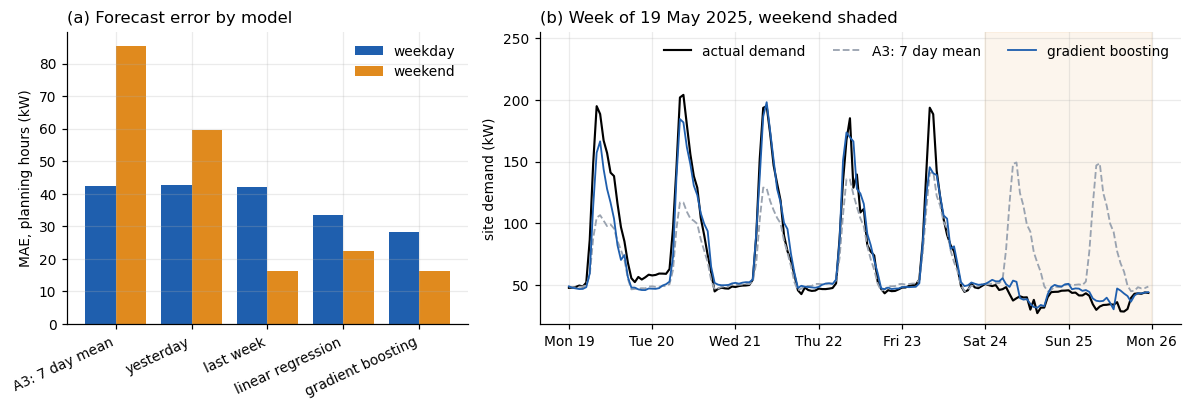

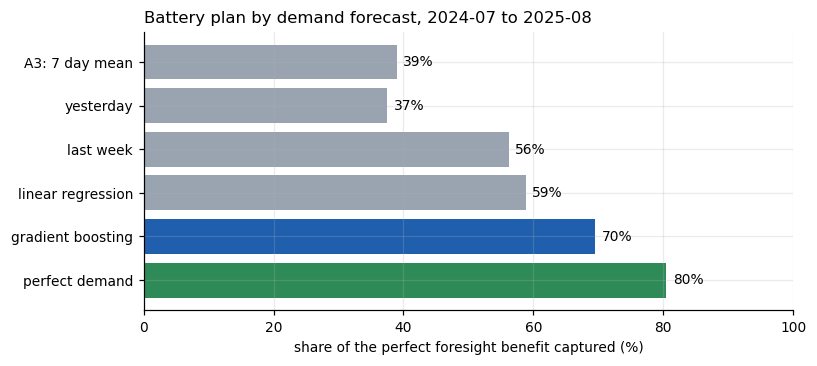

saved  demand_forecasts.parquet            679 kB
saved  demand_model_comparison.csv           1 kB
saved  demand_model_results.md               2 kB
saved  fig15_demand_models.png             104 kB
saved  fig16_demand_dispatch.png            35 kB


In [5]:
# 4 · Figures 15 and 16, and save the results
SHORT = {"A3: 7 day same hour mean": "A3: 7 day mean", "same hour yesterday": "yesterday",
         "same hour last week": "last week", "linear regression": "linear regression",
         "gradient boosting": "gradient boosting"}
GREY, BLUE, ORANGE = "#9AA3B0", "#1F5FAE", "#E08A1E"

# Figure 15: accuracy by model, and one week of forecasts against actual demand
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
mae = pd.DataFrame({"weekday": err[~wk].mean(), "weekend": err[wk].mean()}).rename(index=SHORT)
x = np.arange(len(mae))
ax[0].bar(x - 0.2, mae.weekday, 0.4, color=BLUE, label="weekday")
ax[0].bar(x + 0.2, mae.weekend, 0.4, color=ORANGE, label="weekend")
ax[0].set_xticks(x, mae.index, rotation=25, ha="right")
ax[0].set_ylabel("MAE, planning hours (kW)"); ax[0].legend(frameon=False)
ax[0].set_title("(a) Forecast error by model", loc="left")

wk_start = pd.Timestamp("2025-05-19")                     # a Monday, same season as Figure 14
win = pred.loc[wk_start: wk_start + pd.Timedelta("7D") - pd.Timedelta("1h")]
ax[1].plot(win.index, win.actual, color="black", lw=1.4, label="actual demand")
ax[1].plot(win.index, win["A3: 7 day same hour mean"], color=GREY, lw=1.2, ls="--", label="A3: 7 day mean")
ax[1].plot(win.index, win["gradient boosting"], color=BLUE, lw=1.2, label="gradient boosting")
ax[1].axvspan(wk_start + pd.Timedelta("5D"), wk_start + pd.Timedelta("7D"), color=ORANGE, alpha=.08)
ax[1].set_ylim(top=win[["actual", "A3: 7 day same hour mean", "gradient boosting"]].max().max() * 1.25)
ax[1].set_ylabel("site demand (kW)"); ax[1].legend(frameon=False, ncol=3, loc="upper right")
ax[1].set_title(f"(b) Week of {wk_start:%d %b %Y}, weekend shaded", loc="left")
ax[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d"))
fig.tight_layout(); fig.savefig(FIG/"fig15_demand_models.png"); plt.show()

# Figure 16: what each demand forecast is worth to the battery plan
order = ["forecast plan, demand: " + m for m in MODELS] + ["forecast plan, demand: perfect demand"]
share = disp.loc[order, "share_of_perfect_%"].rename(lambda k: SHORT.get(k.split(": ", 1)[1], k.split(": ", 1)[1]))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(share.index, share.values, color=[GREY] * 4 + [BLUE, "#2E8B57"])
for i, v in enumerate(share.values):
    ax.text(v + 1, i, f"{v:.0f}%", va="center")
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("share of the perfect foresight benefit captured (%)")
ax.set_title(f"Battery plan by demand forecast, {TEST_START[:7]} to {s.index.max():%Y-%m}", loc="left")
fig.tight_layout(); fig.savefig(FIG/"fig16_demand_dispatch.png"); plt.show()

# save forecasts (used by the dashboard) and a results summary
pred.to_parquet(PROC/"demand_forecasts.parquet")
res.to_csv(OUT/"demand_model_comparison.csv")

def md(df, digits=1):
    df = df.round(digits).reset_index()
    lines = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    return "\n".join(lines + ["| " + " | ".join("" if pd.isna(v) else str(v) for v in r) + " |"
                              for r in df.itertuples(index=False)])

flat = res.copy(); flat.columns = [f"{a} {b}" for a, b in flat.columns]
report = f"""# Demand forecast comparison (notebook 07)

Out of sample, walk forward with monthly refits on an expanding window, {TEST_START} to {pred.index.max():%d %b %Y}.
Inputs are known by 22:00 the evening before: demand at the same hour 1, 2 and 7 days earlier, the A3 7 day mean,
temperature at the same hour yesterday, hour, weekday, weekend and month.

## Accuracy
{md(flat.rename_axis("model"))}

## Planning hour MAE by day type (kW)
{md(pd.DataFrame({"weekday": err[~wk].mean(), "weekend": err[wk].mean()}).rename_axis("model"))}

## Battery plan with each demand forecast (solar caution {CAUTION})
{md(disp.rename_axis("strategy"), 1)}

Best model: {best_model}. Saving {a3['saving_vs_no_battery_%']:.1f}% to {nb['saving_vs_no_battery_%']:.1f}%,
value of the forecast ${a3['value_vs_best_rule_$']:,.0f} to ${nb['value_vs_best_rule_$']:,.0f},
share of the perfect foresight benefit {a3['share_of_perfect_%']:.0f}% to {nb['share_of_perfect_%']:.0f}%.

Figures: fig15_demand_models.png, fig16_demand_dispatch.png
"""
(OUT/"demand_model_results.md").write_text(report)
for p in [PROC/"demand_forecasts.parquet", OUT/"demand_model_comparison.csv",
          OUT/"demand_model_results.md", FIG/"fig15_demand_models.png", FIG/"fig16_demand_dispatch.png"]:
    print(f"saved  {p.name:<30} {p.stat().st_size/1e3:8,.0f} kB")